# Data Table Preparation

Merge the 4 tables and build the aggregated engagement table used for modeling.

In [1]:
from pathlib import Path
import pandas as pd

# works from notebooks/ (Jupyter) or the repo root (e.g. Colab after git clone + %cd)
DATA_DIR = Path('../data') if Path('../data').exists() else Path('data')

In [2]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

In [3]:
ad_events_df = pd.read_csv(DATA_DIR / 'ad_events.csv')
ads_df = pd.read_csv(DATA_DIR / 'ads.csv')
users_df = pd.read_csv(DATA_DIR / 'users.csv')
campaigns_df = pd.read_csv(DATA_DIR / 'campaigns.csv')

In [4]:
ads_df_clean = ads_df.drop_duplicates(subset=['ad_id'])
df_merged_prep = pd.merge(ad_events_df, ads_df_clean, on='ad_id', how='left')
df_merged_prep['timestamp'] = pd.to_datetime(df_merged_prep['timestamp'])
df_merged_prep['hour_of_day'] = df_merged_prep['timestamp'].dt.hour

# TABLE

In [5]:
ads_df_clean = ads_df.drop_duplicates(subset=['ad_id'])
users_df_clean = users_df.drop_duplicates(subset=['user_id'])

df_merged = pd.merge(ad_events_df, ads_df_clean, on='ad_id', how='left')

df_merged = pd.merge(
    df_merged,
    users_df_clean[['user_id']],
    on='user_id',
    how='left'
)
final_columns_for_ml = [
    'event_id',
    'ad_platform',
    'ad_type',
    'day_of_week',
    'event_type',

]

df_final_ml_ready = df_merged[final_columns_for_ml].copy()

df_final_ml_ready

,event_id,ad_platform,ad_type,day_of_week,event_type
0,1,Facebook,Stories,Saturday,Like
1,2,Instagram,Carousel,Sunday,Share
2,3,Instagram,Carousel,Friday,Impression
3,4,Instagram,Image,Thursday,Impression
4,5,Instagram,Stories,Tuesday,Impression
...,...,...,...,...,...
399995,399996,Facebook,Carousel,Friday,Impression
399996,399997,Instagram,Carousel,Saturday,Impression
399997,399998,Facebook,Stories,Sunday,Click
399998,399999,Facebook,Stories,Friday,Impression


In [6]:
df_engaged_by_day = df_merged.groupby(['day_of_week', 'time_of_day', 'ad_platform', 'ad_type']).agg(
    engaged=('event_type', 'count')
).reset_index()

display(df_engaged_by_day)

,day_of_week,time_of_day,ad_platform,ad_type,engaged
0,Friday,Afternoon,Facebook,Carousel,2057
1,Friday,Afternoon,Facebook,Image,2132
2,Friday,Afternoon,Facebook,Stories,3018
3,Friday,Afternoon,Facebook,Video,1904
4,Friday,Afternoon,Instagram,Carousel,1627
...,...,...,...,...,...
219,Wednesday,Night,Facebook,Video,1958
220,Wednesday,Night,Instagram,Carousel,1631
221,Wednesday,Night,Instagram,Image,1564
222,Wednesday,Night,Instagram,Stories,1554


# Fix

In [7]:
ads_df_clean = ads_df.drop_duplicates(subset=['ad_id'])
users_df_clean = users_df.drop_duplicates(subset=['user_id'])
campaigns_df_clean = campaigns_df.drop_duplicates(subset=['campaign_id'])

df_merged = pd.merge(ad_events_df, ads_df_clean, on='ad_id', how='left')
df_merged = pd.merge(
    df_merged,
    users_df_clean[['user_id', 'user_gender']],
    on='user_id',
    how='left'
)

df_merged = pd.merge(
    df_merged,
    campaigns_df_clean[['campaign_id', 'total_budget']],
    on='campaign_id',
    how='left'
)

df_engaged = df_merged[df_merged['event_type'].isin(['Click', 'Like', 'Share','Impression','Purchase'])].copy()

df_grouped = df_engaged.groupby(['day_of_week', 'time_of_day', 'ad_platform', 'ad_type', 'target_gender', 'campaign_id']).agg(
    engaged=('event_type', 'count')
).reset_index()

df_grouped = pd.merge(
    df_grouped,
    campaigns_df_clean[['campaign_id', 'total_budget']],
    on='campaign_id',
    how='left'
)


final_columns_for_ml = [
    'day_of_week',
    'time_of_day',
    'ad_platform',
    'ad_type',
    'target_gender',
    'total_budget',
    'engaged'
]

df_final_ml_ready = df_grouped[final_columns_for_ml].copy()

display(df_final_ml_ready)

correlation = df_final_ml_ready['total_budget'].corr(df_final_ml_ready['engaged'])
print(f'Correlation between total_budget and engaged: {correlation:.4f}')

,day_of_week,time_of_day,ad_platform,ad_type,target_gender,total_budget,engaged
0,Friday,Afternoon,Facebook,Carousel,All,40094.07,73
1,Friday,Afternoon,Facebook,Carousel,All,21855.42,74
2,Friday,Afternoon,Facebook,Carousel,All,98904.66,66
3,Friday,Afternoon,Facebook,Carousel,All,56692.87,69
4,Friday,Afternoon,Facebook,Carousel,All,59264.68,75
...,...,...,...,...,...,...,...
5091,Wednesday,Night,Instagram,Video,All,35743.40,75
5092,Wednesday,Night,Instagram,Video,Female,45326.60,63
5093,Wednesday,Night,Instagram,Video,Female,81744.53,77
5094,Wednesday,Night,Instagram,Video,Female,59264.68,62


Correlation between total_budget and engaged: 0.0845


In [8]:
df_final_ml_ready.sort_values(by='engaged', ascending=False)

,day_of_week,time_of_day,ad_platform,ad_type,target_gender,total_budget,engaged
2373,Sunday,Evening,Facebook,Carousel,All,71038.28,236
4375,Wednesday,Afternoon,Facebook,Carousel,All,71038.28,233
4011,Tuesday,Morning,Facebook,Carousel,All,71038.28,228
1281,Monday,Night,Facebook,Carousel,All,71038.28,227
4193,Tuesday,Night,Facebook,Carousel,All,71038.28,224
...,...,...,...,...,...,...,...
1616,Saturday,Afternoon,Instagram,Stories,All,7918.04,46
2228,Sunday,Afternoon,Facebook,Image,Female,13842.07,46
1925,Saturday,Morning,Facebook,Video,Male,14343.25,45
3370,Thursday,Morning,Facebook,Video,All,94023.76,42


# PLOT

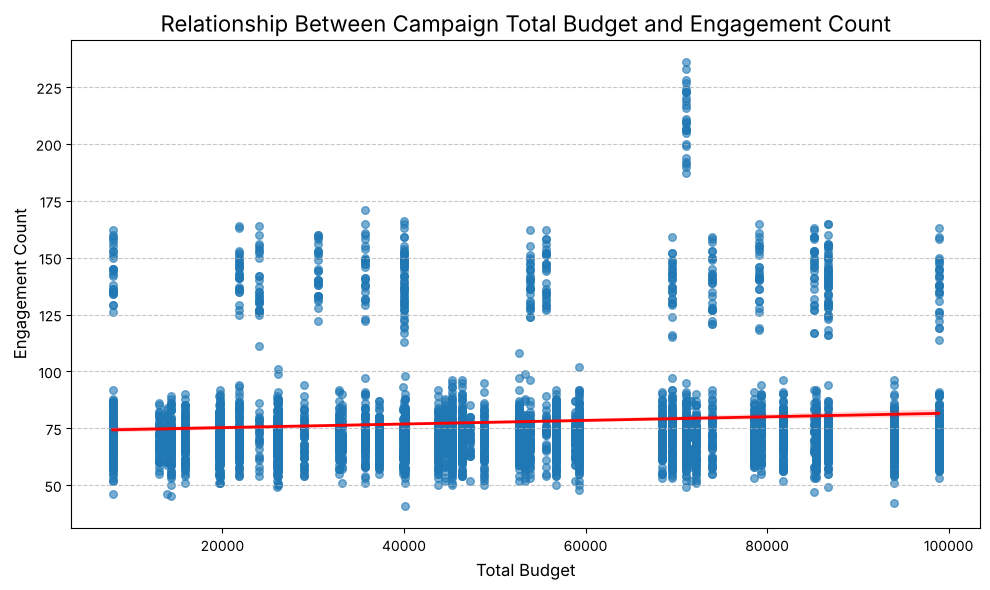

In [9]:
plt.figure(figsize=(10, 6))
sns.regplot(
    x='total_budget',
    y='engaged',
    data=df_final_ml_ready,
    scatter_kws={'alpha':0.6, 's':30, 'color':'#1f77b4'},
    line_kws={'color':'red', 'linewidth': 2}
)

plt.title('Relationship Between Campaign Total Budget and Engagement Count', fontsize=16)
plt.xlabel('Total Budget', fontsize=12)
plt.ylabel('Engagement Count', fontsize=12)
plt.grid(axis='y', linestyle='--', alpha=0.7)
plt.tight_layout()
plt.show()

/tmp/ipykernel_567/3713011394.py:6: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(


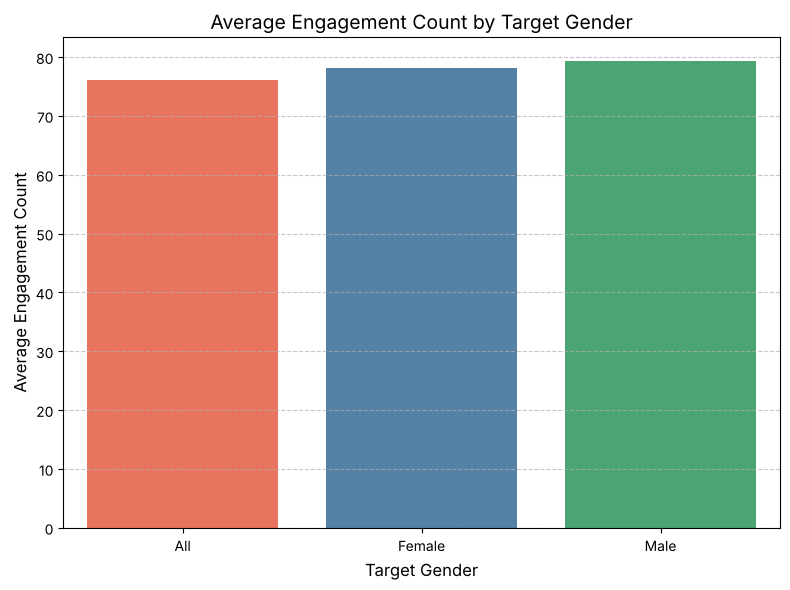

In [10]:
df_gender_engaged = df_final_ml_ready.groupby('target_gender').agg(
    avg_engaged=('engaged', 'mean')
).reset_index()

plt.figure(figsize=(8, 6))
sns.barplot(
    x='target_gender',
    y='avg_engaged',
    data=df_gender_engaged,
    palette=['#FF6347', '#4682B4', '#3CB371']
)

plt.title('Average Engagement Count by Target Gender', fontsize=14)
plt.xlabel('Target Gender', fontsize=12)
plt.ylabel('Average Engagement Count', fontsize=12)
plt.grid(axis='y', linestyle='--', alpha=0.7)
plt.tight_layout()
plt.show()

<Figure size 1200x700 with 0 Axes>

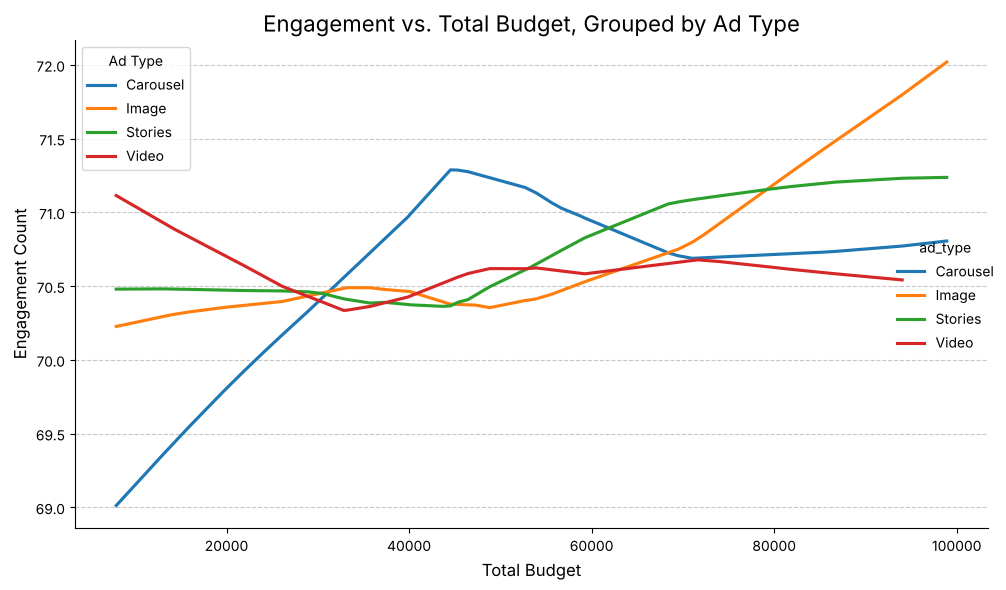

In [11]:
plt.figure(figsize=(12, 7))

sns.lmplot(
    x='total_budget',
    y='engaged',
    hue='ad_type',
    data=df_final_ml_ready,
    lowess=True,
    scatter=False,
    height=6,
    aspect=1.5
)
plt.title('Engagement vs. Total Budget, Grouped by Ad Type', fontsize=16)
plt.xlabel('Total Budget', fontsize=12)
plt.ylabel('Engagement Count', fontsize=12)
plt.grid(axis='y', linestyle='--', alpha=0.7)
plt.legend(title='Ad Type')
plt.tight_layout()
plt.show()